In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Xác định thư mục gốc của dự án
ROOT_DIR = Path().resolve().parent  # Nếu notebook nằm trong thư mục notebooks/
RAW_IMG_DIR = ROOT_DIR / "data" / "raw"

# Kiểm tra thử một file ảnh bất kỳ trong các folder ảnh gốc
sample_img_path = None
for root, _, files in os.walk(RAW_IMG_DIR):
    for file in files:
        if file.endswith(".jpg"):
            sample_img_path = os.path.join(root, file)
            break
    if sample_img_path:
        break

print(f"Đang dùng ảnh mẫu để kiểm tra: {sample_img_path}")

Đang dùng ảnh mẫu để kiểm tra: D:\Projects\Workspace\skin-cancer-detection\data\raw\HAM10000_images_part_1\ISIC_0024306.jpg


In [2]:
def inspect_crop_roi(image_path: str):
    """
    Trực quan hóa và so sánh ảnh gốc với ảnh sau khi đã thực hiện Crop ROI 
    (cắt bỏ viền đen/vùng ngoài để tập trung vào nốt ruồi).
    """
    # 1. Đọc ảnh gốc bằng OpenCV
    original_image = cv2.imread(image_path)
    if original_image is None:
        print(f"Không thể đọc file ảnh tại: {image_path}")
        return
        
    # Chuyển BGR sang RGB để hiển thị đúng màu trên Matplotlib
    orig_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
    
    # 2. Áp dụng logic thuật toán crop_lesion_roi
    gray = cv2.cvtColor(original_image, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 15, 255, cv2.THRESH_BINARY)
    
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cropped_rgb = orig_rgb.copy()
    
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        
        img_h, img_w = original_image.shape[:2]
        if w > int(img_w * 0.3) and h > int(img_h * 0.3):
            cropped_bgr = original_image[y:y+h, x:x+w]
            cropped_rgb = cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2RGB)

    # 3. Vẽ biểu đồ so sánh song song
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
    axes[0].imshow(orig_rgb)
    axes[0].set_title("1. Ảnh Gốc (Original)")
    axes[0].axis('off')
    
    axes[1].imshow(cropped_rgb)
    axes[1].set_title("2. Sau khi Crop ROI (Tập trung tổn thương)")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

    return orig_rgb, cropped_rgb


In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def inspect_hair_removal(image_bgr: np.ndarray):
    """
    Nhận đầu vào là ảnh BGR (đã qua bước Crop ROI), 
    thực hiện khử lông bằng DullRazor và trực quan hóa các bước.
    """
    if image_bgr is None:
        raise ValueError("Ảnh đầu vào cho bước khử lông đang bị trống (None)!")
    
    # Chuyển sang RGB để hiển thị đúng màu bằng Matplotlib
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    
    # Bước 1: Chuyển sang ảnh xám
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    
    # Bước 2: Dùng bộ lọc Blackhat để tách nét mảnh (tóc/lông)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    
    # Bước 3: Tạo Mask nhị phân
    _, thresh = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    
    # Bước 4: Inpainting trên ảnh đã cắt ROI
    cleaned_bgr = cv2.inpaint(image_bgr, thresh, inpaintRadius=3, flags=cv2.INPAINT_TELEA)
    cleaned_rgb = cv2.cvtColor(cleaned_bgr, cv2.COLOR_BGR2RGB)
    
    # --- Trực quan hóa kết quả qua các bước ---
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    axes[0].imshow(image_rgb)
    axes[0].set_title("1. Ảnh sau khi Crop ROI")
    axes[0].axis('off')
    
    axes[1].imshow(gray, cmap='gray')
    axes[1].set_title("2. Ảnh Xám (Grayscale)")
    axes[1].axis('off')
    
    axes[2].imshow(thresh, cmap='gray')
    axes[2].set_title("3. Mặt nạ tóc (Hair Mask)")
    axes[2].axis('off')
    
    axes[3].imshow(cleaned_rgb)
    axes[3].set_title("4. Sau khi khử lông (Cleaned)")
    axes[3].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # TRẢ VỀ ẢNH ĐÃ KHỬ LÔNG (dạng BGR) để tiếp tục chuyển sang bước CLAHE
    return cleaned_bgr

--- Đang kiểm tra hiệu ứng Color Constancy ---


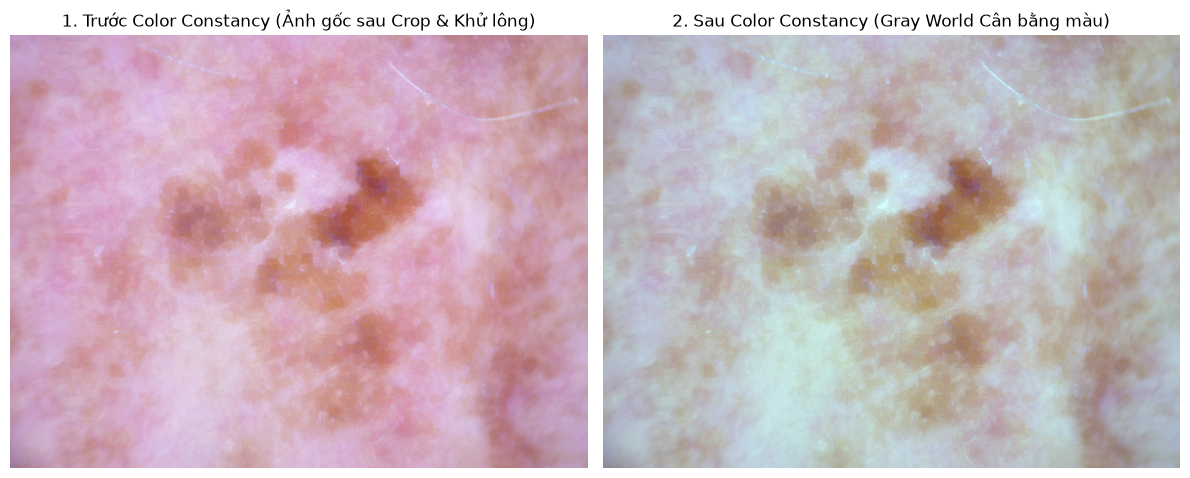

In [8]:
def apply_gray_world_assumption(image_bgr: np.ndarray) -> np.ndarray:
    """
    Thuật toán Gray World Color Constancy giúp chuẩn hóa màu sắc,
    loại bỏ hiện tượng ám màu do ánh sáng thiết bị chụp da liễu.
    """
    result = image_bgr.astype(np.float32)
    # Tính giá trị trung bình trên 3 kênh B, G, R
    average_b = np.mean(result[:, :, 0])
    average_g = np.mean(result[:, :, 1])
    average_r = np.mean(result[:, :, 2])
    
    # Tính hệ số cân bằng trung bình toàn cục
    average_gray = (average_b + average_g + average_r) / 3.0
    
    # Co giãn lại các kênh màu
    result[:, :, 0] = np.clip(result[:, :, 0] * (average_gray / average_b), 0, 255)
    result[:, :, 1] = np.clip(result[:, :, 1] * (average_gray / average_g), 0, 255)
    result[:, :, 2] = np.clip(result[:, :, 2] * (average_gray / average_r), 0, 255)
    
    return result.astype(np.uint8)

def inspect_color_constancy(cleaned_bgr):
    """
    Trực quan hóa so sánh ảnh trước và sau khi áp dụng Color Constancy (Gray World).
    """
    # 1. Áp dụng chuẩn hóa màu sắc
    color_balanced_bgr = apply_gray_world_assumption(cleaned_bgr)
    
    # 2. Chuyển đổi sang RGB để hiển thị qua Matplotlib
    orig_rgb = cv2.cvtColor(cleaned_bgr, cv2.COLOR_BGR2RGB)
    balanced_rgb = cv2.cvtColor(color_balanced_bgr, cv2.COLOR_BGR2RGB)
    
    # 3. Vẽ biểu đồ so sánh song song
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
    axes[0].imshow(orig_rgb)
    axes[0].set_title("1. Trước Color Constancy (Ảnh gốc sau Crop & Khử lông)")
    axes[0].axis('off')
    
    axes[1].imshow(balanced_rgb)
    axes[1].set_title("2. Sau Color Constancy (Gray World Cân bằng màu)")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    return color_balanced_bgr

# --- Chạy thử nghiệm kiểm tra Color Constancy trong chuỗi liên hoàn ---
print("--- Đang kiểm tra hiệu ứng Color Constancy ---")
# Giả định biến 'cleaned_image' đã có sẵn từ bước khử lông trước đó
if 'cleaned_image' in locals():
    balanced_image = inspect_color_constancy(cleaned_image)
else:
    print("Vui lòng chạy các bước Crop ROI và Khử lông ở các ô trước để có biến 'cleaned_image'.")

In [4]:
def inspect_clahe(cleaned_bgr):
    # --- CÔNG ĐOẠN CLAHE TRÊN KHÔNG GIAN MÀU LAB ---
    # Chuyển ảnh sạch lông sang không gian màu LAB
    lab = cv2.cvtColor(cleaned_bgr, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    
    # Áp dụng CLAHE riêng cho kênh độ sáng (L - Lightness)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l_channel)
    
    # Gộp lại kênh L đã cân bằng sáng với các kênh a, b ban đầu
    lab_clahe = cv2.merge((l_clahe, a_channel, b_channel))
    
    # Chuyển ngược lại không gian màu BGR
    final_bgr = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2BGR)
    
    # Chuyển đổi các ảnh sang RGB để hiển thị chính xác qua Matplotlib
    hair_removed_rgb = cv2.cvtColor(cleaned_bgr, cv2.COLOR_BGR2RGB)
    l_channel_rgb = l_channel 
    l_clahe_rgb = l_clahe     
    final_rgb = cv2.cvtColor(final_bgr, cv2.COLOR_BGR2RGB)
    
    # --- Trực quan hóa chi tiết từng bước CLAHE ---
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    axes[0].imshow(hair_removed_rgb)
    axes[0].set_title("1. Ảnh sạch lông (Input)")
    axes[0].axis('off')
    
    axes[1].imshow(l_channel_rgb, cmap='gray')
    axes[1].set_title("2. Kênh độ sáng L (LAB)")
    axes[1].axis('off')
    
    axes[2].imshow(l_clahe_rgb, cmap='gray')
    axes[2].set_title("3. Kênh L sau khi chạy CLAHE")
    axes[2].axis('off')
    
    axes[3].imshow(final_rgb)
    axes[3].set_title("4. Ảnh hoàn thiện (Enhanced)")
    axes[3].axis('off')
    
    plt.tight_layout()
    plt.show()

    return cleaned_bgr

    

--- Đang chạy bước 1: Đọc ảnh và Cắt viền ROI ---

--- Đang chạy bước 2: Khử lông (DullRazor) ---


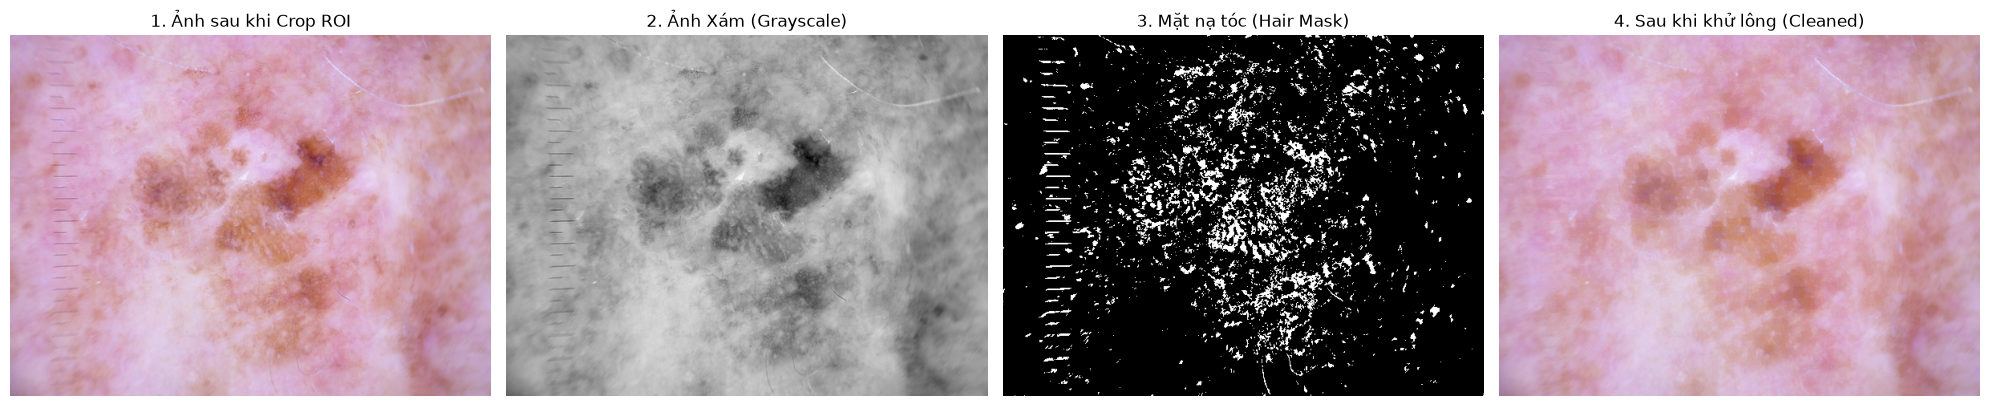


--- Đang chạy bước 3: Tăng cường tương phản CLAHE ---

--- Đang chạy bước 4: Kiểm tra Albumentations Augmentations ---


d:\Projects\Workspace\skin-cancer-detection\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


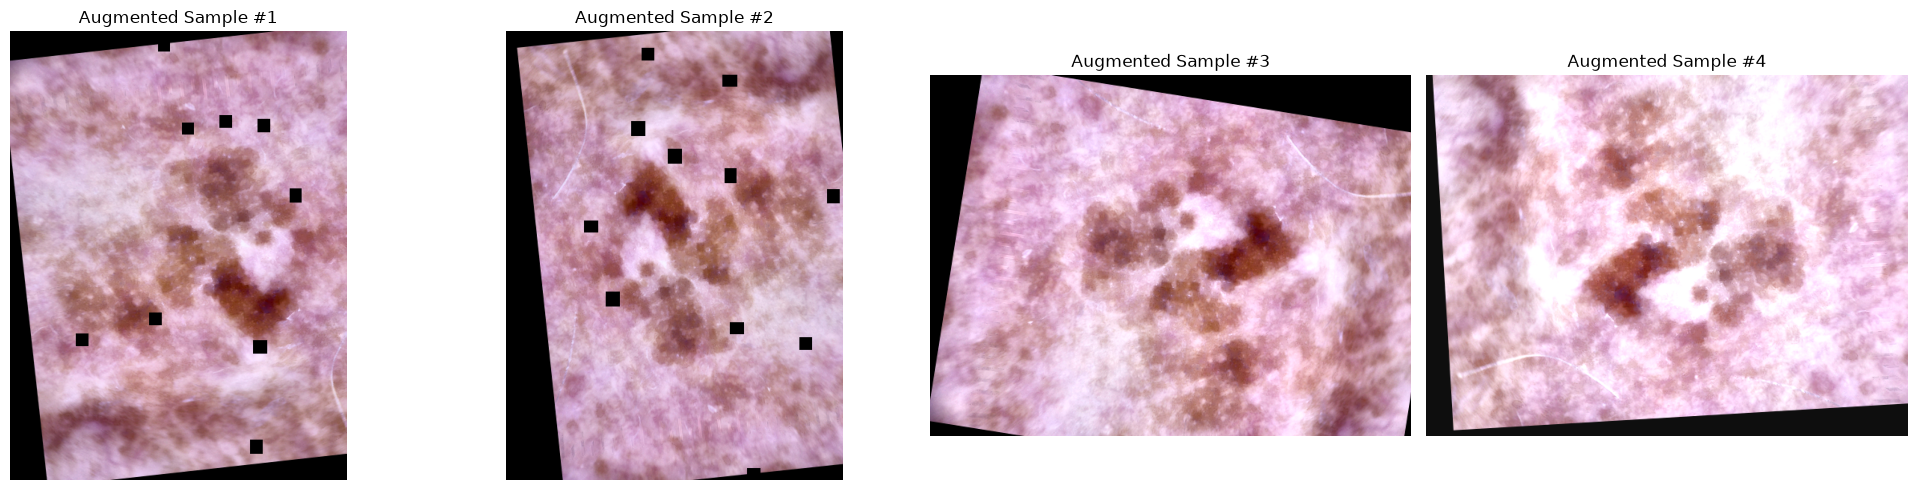

In [5]:
import albumentations as A
import numpy as np
import matplotlib.pyplot as plt
import cv2

def inspect_albumentations(cleaned_bgr, num_samples=4):
    """
    Áp dụng và trực quan hóa các biến thể tăng cường dữ liệu (Augmentation) 
    từ thư viện Albumentations trên ảnh đã qua Crop ROI, khử lông và CLAHE.
    """
    # 1. Định nghĩa pipeline tăng cường đồng bộ chuẩn Albumentations v2.0+
    train_transform = A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.8, border_mode=cv2.BORDER_CONSTANT),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
        # CoarseDropout (Cutout) cập nhật theo chuẩn tuple mới
        A.CoarseDropout(num_holes_range=(8, 12), hole_height_range=(16, 20), hole_width_range=(16, 20), p=0.5),
    ])

    # Chuyển ảnh đầu vào từ BGR sang RGB để hiển thị đúng màu với Albumentations/Matplotlib
    image_rgb = cv2.cvtColor(cleaned_bgr, cv2.COLOR_BGR2RGB)

    # 2. Sinh ra các biến thể ngẫu nhiên
    fig, axes = plt.subplots(1, num_samples, figsize=(20, 5))
    
    for i in range(num_samples):
        # Albumentations nhận đầu vào là keyword argument 'image'
        augmented = train_transform(image=image_rgb)
        augmented_img = augmented['image']
        
        axes[i].imshow(augmented_img)
        axes[i].set_title(f"Augmented Sample #{i+1}")
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

# --- Thực thi kiểm tra liên hoàn toàn bộ Pipeline trong Notebook ---
sample_img_path = "../data/raw/HAM10000_images_part_1/ISIC_0027419.jpg"

if sample_img_path:
    print("--- Đang chạy bước 1: Đọc ảnh và Cắt viền ROI ---")
    orig_img = cv2.imread(sample_img_path)
    
    gray = cv2.cvtColor(orig_img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 15, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    cropped_bgr = orig_img.copy()
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        img_h, img_w = orig_img.shape[:2]
        if w > int(img_w * 0.3) and h > int(img_h * 0.3):
            cropped_bgr = orig_img[y:y+h, x:x+w]

    print("\n--- Đang chạy bước 2: Khử lông (DullRazor) ---")
    cleaned_image = inspect_hair_removal(cropped_bgr)
    
    print("\n--- Đang chạy bước 3: Tăng cường tương phản CLAHE ---")
    lab = cv2.cvtColor(cleaned_image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l)
    enhanced_bgr = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)
    
    print("\n--- Đang chạy bước 4: Kiểm tra Albumentations Augmentations ---")
    inspect_albumentations(enhanced_bgr, num_samples=4)
else:
    print("Không tìm thấy file ảnh mẫu!")

--- BƯỚC 1: Đọc ảnh và Cắt viền ROI ---


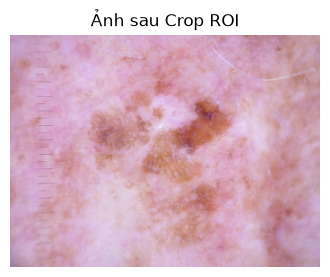


--- BƯỚC 2: Khử lông (DullRazor) trên ảnh đã crop ---


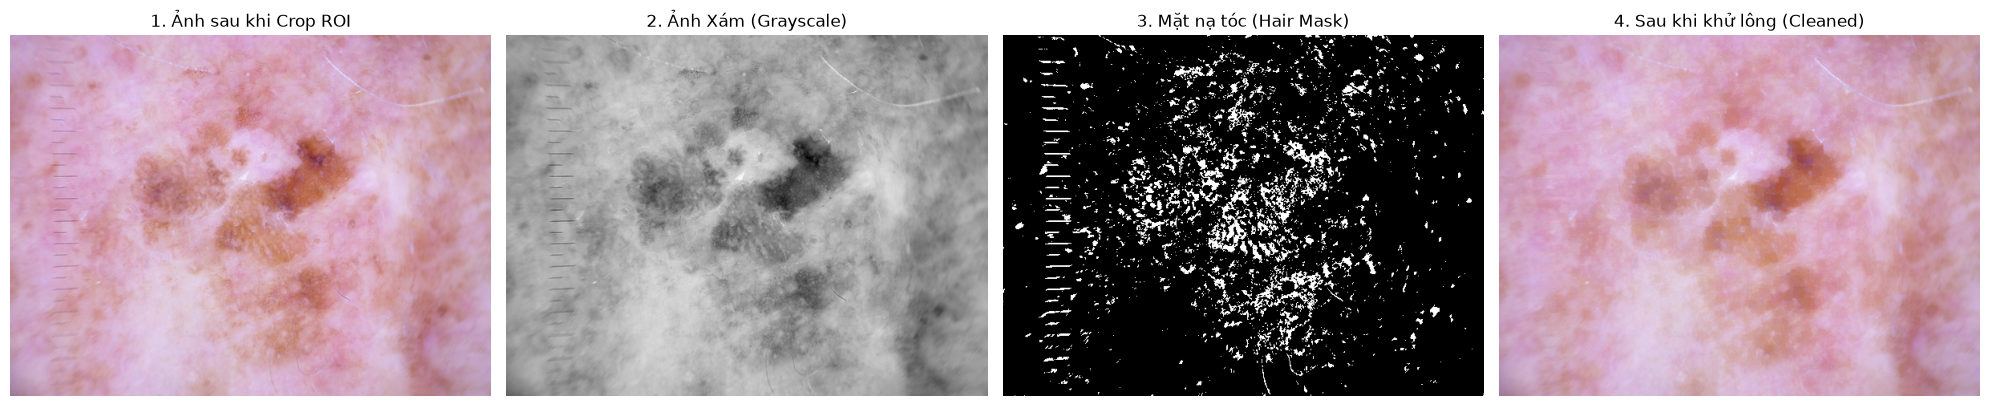


--- BƯỚC 3: Tăng cường tương phản CLAHE ---


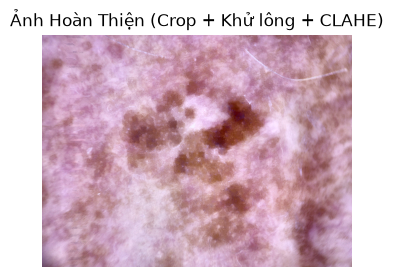


--- BƯỚC 4: Kiểm tra Albumentations Augmentations ---


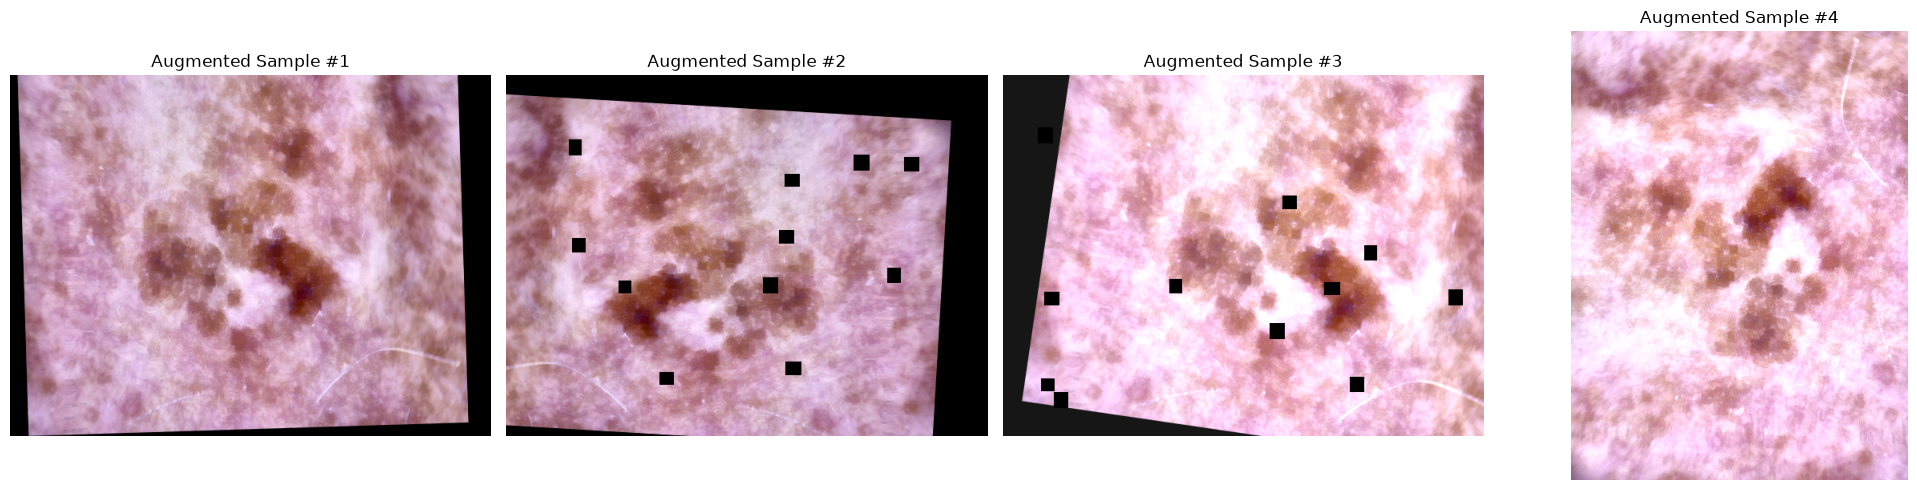

In [7]:
# 1. Định nghĩa đường dẫn ảnh mẫu
sample_img_path = "../data/raw/HAM10000_images_part_1/ISIC_0027419.jpg"

print("--- BƯỚC 1: Đọc ảnh và Cắt viền ROI ---")
orig_img = cv2.imread(sample_img_path)
# Gọi logic crop ROI trực tiếp
gray = cv2.cvtColor(orig_img, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(gray, 15, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

cropped_bgr = orig_img.copy()
if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest_contour)
    img_h, img_w = orig_img.shape[:2]
    if w > int(img_w * 0.3) and h > int(img_h * 0.3):
        cropped_bgr = orig_img[y:y+h, x:x+w]

# Hiển thị ảnh sau khi crop ROI
plt.figure(figsize=(4, 4))
plt.imshow(cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2RGB))
plt.title("Ảnh sau Crop ROI")
plt.axis('off')
plt.show()

print("\n--- BƯỚC 2: Khử lông (DullRazor) trên ảnh đã crop ---")
cleaned_image = inspect_hair_removal(cropped_bgr)

print("\n--- BƯỚC 3: Tăng cường tương phản CLAHE ---")
lab = cv2.cvtColor(cleaned_image, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
l_clahe = clahe.apply(l)
enhanced_bgr = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

# Hiển thị kết quả cuối cùng hoàn thiện
plt.figure(figsize=(4, 4))
plt.imshow(cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2RGB))
plt.title("Ảnh Hoàn Thiện (Crop + Khử lông + CLAHE)")
plt.axis('off')
plt.show()

print("\n--- BƯỚC 4: Kiểm tra Albumentations Augmentations ---")
inspect_albumentations(enhanced_bgr, num_samples=4)